# PTB-XL: 1D CNN vs 1D ResNet on PTB-XL (five superclasses)

Runs the whole experiment on a Kaggle GPU: install the package from GitHub, get PTB-XL 1.0.3, prepare the 100 Hz signals with the official patient-level folds (1–8 train, 9 validation, 10 test), train both models with five seeds, and compare them with patient-level bootstrap intervals and selective-prediction curves.

**Settings:** Accelerator **GPU T4 x2** (or P100) and **Internet on**. Outputs are written to `/kaggle/working/reports`.

In [1]:
import subprocess, sys
subprocess.run(["git", "clone", "-q", "https://github.com/MHKhan50/ptbxl-ecg-superclass-benchmark.git", "/kaggle/working/ptbxl-bench"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/kaggle/working/ptbxl-bench"], check=True)
import os
os.chdir("/kaggle/working/ptbxl-bench")
# The kernel started before the install, so add the package source to the path directly.
sys.path.insert(0, "/kaggle/working/ptbxl-bench/src")
import cardionet
print("cardionet", cardionet.__version__)
print(subprocess.run(["git", "log", "-1", "--format=%h %s"], capture_output=True, text=True).stdout)

cardionet 0.2.0
9d9a721 Keep the best checkpoints in the Kaggle output; store the notebook without outputs



## 1. PTB-XL 1.0.3
Uses an attached Kaggle copy if one is found under `/kaggle/input`; otherwise downloads the two metadata files and the 100 Hz records from PhysioNet (takes a while the first time).

In [2]:
import glob, urllib.request, zipfile, pathlib
BASE = "https://physionet.org/files/ptb-xl/1.0.3/"
found = glob.glob("/kaggle/input/**/ptbxl_database.csv", recursive=True)
if found:
    DATA_DIR = str(pathlib.Path(found[0]).parent)
else:
    # Official PhysioNet copy: the two metadata files plus only the 100 Hz records.
    DATA_DIR = "/kaggle/working/ptbxl"
    os.makedirs(DATA_DIR, exist_ok=True)
    for name in ["ptbxl_database.csv", "scp_statements.csv"]:
        urllib.request.urlretrieve(BASE + name, os.path.join(DATA_DIR, name))
    import pandas as pd
    from concurrent.futures import ThreadPoolExecutor

    def fetch(relative):
        target = os.path.join(DATA_DIR, relative)
        if not os.path.exists(target):
            os.makedirs(os.path.dirname(target), exist_ok=True)
            for attempt in range(5):
                try:
                    urllib.request.urlretrieve(BASE + relative, target)
                    break
                except Exception:
                    if attempt == 4:
                        raise

    records = pd.read_csv(os.path.join(DATA_DIR, "ptbxl_database.csv"))["filename_lr"].tolist()
    files = [r + ext for r in records for ext in (".hea", ".dat")]
    with ThreadPoolExecutor(max_workers=32) as pool:
        list(pool.map(fetch, files))
    print("downloaded", len(files), "files")
import pandas as pd
db = pd.read_csv(os.path.join(DATA_DIR, "ptbxl_database.csv"))
print(DATA_DIR, "| records:", len(db), "| patients:", db.patient_id.nunique())

downloaded 43598 files
/kaggle/working/ptbxl | records: 21799 | patients: 18869


## 2. Prepare signals (official folds, training-only normalisation)

In [3]:
from cardionet.data import prepare_ptbxl
import json
meta = prepare_ptbxl(DATA_DIR, "data/processed", sampling_rate=100)
print(json.dumps(meta, indent=2))

{
  "signals_file": "signals_normalized.npy",
  "records_after_label_filter": 21388,
  "shape": [
    21388,
    12,
    1000
  ],
  "labels": [
    "NORM",
    "MI",
    "STTC",
    "CD",
    "HYP"
  ],
  "sampling_rate": 100,
  "train_records": 17084,
  "validation_records": 2146,
  "test_records": 2158,
  "seed": 17,
  "patient_overlap": false,
  "dataset": "PTB-XL 1.0.3"
}


## 3. Train both models with five seeds
Early stopping on validation loss (patience 5, up to 40 epochs). Thresholds are chosen per label on the validation fold and then frozen for the test fold.

In [4]:
import torch, time
from cardionet.train import run_training
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
SEEDS = [17, 23, 31, 47, 59]
results = {}
for model in ["cnn", "resnet"]:
    for seed in SEEDS:
        t0 = time.time()
        m = run_training("configs/default.yaml", model, epochs=40, checkpoint_dir="checkpoints", seed=seed)
        results[(model, seed)] = m["macro_auroc"]
        print(f"{model} seed {seed}: macro AUROC {m['macro_auroc']:.4f} ({time.time() - t0:.0f} s)")

GPU: Tesla T4


/kaggle/working/ptbxl-bench/src/cardionet/data.py:147: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(self.x[i]), torch.from_numpy(self.y[i])


epoch=1/40 train_loss=0.35620 val_loss=0.32403
epoch=2/40 train_loss=0.30921 val_loss=0.31145
epoch=3/40 train_loss=0.29452 val_loss=0.29539
epoch=4/40 train_loss=0.28544 val_loss=0.34849
epoch=5/40 train_loss=0.28074 val_loss=0.30606
epoch=6/40 train_loss=0.27509 val_loss=0.27671
epoch=7/40 train_loss=0.26983 val_loss=0.28749
epoch=8/40 train_loss=0.26930 val_loss=0.29558
epoch=9/40 train_loss=0.26402 val_loss=0.28031
epoch=10/40 train_loss=0.26197 val_loss=0.28222
epoch=11/40 train_loss=0.25827 val_loss=0.27926
{
  "macro_f1": 0.7395637284636368,
  "micro_f1": 0.7705871980250397,
  "macro_precision": 0.7417126597193249,
  "macro_recall": 0.7442402197219892,
  "macro_auroc": 0.9159996203369459,
  "per_label_auroc": {
    "NORM": 0.9385966970372397,
    "MI": 0.914278606965174,
    "STTC": 0.9322809736925723,
    "CD": 0.9075419238383605,
    "HYP": 0.8872999001513834
  },
  "per_label_average_precision": {
    "NORM": 0.9147696558712993,
    "MI": 0.805390513468642,
    "STTC": 0.8193

## 4. Compare

| Model | Seeds | Macro AUROC, mean ± SD over seeds | Seed-ensemble macro AUROC [95% CI] | Macro F1 at 100% / 80% / 50% coverage |
|---|---|---|---|---|
| cnn | 5 | 0.9184 ± 0.0022 | 0.9227 [0.9148, 0.9305] | 0.748 / 0.770 / 0.794 |
| resnet | 5 | 0.9250 ± 0.0030 | 0.9317 [0.9242, 0.9387] | 0.757 / 0.784 / 0.807 |

ResNet minus CNN (seed ensembles): +0.0090 [+0.0068, +0.0113]; ResNet higher in 4 of 5 seeds.


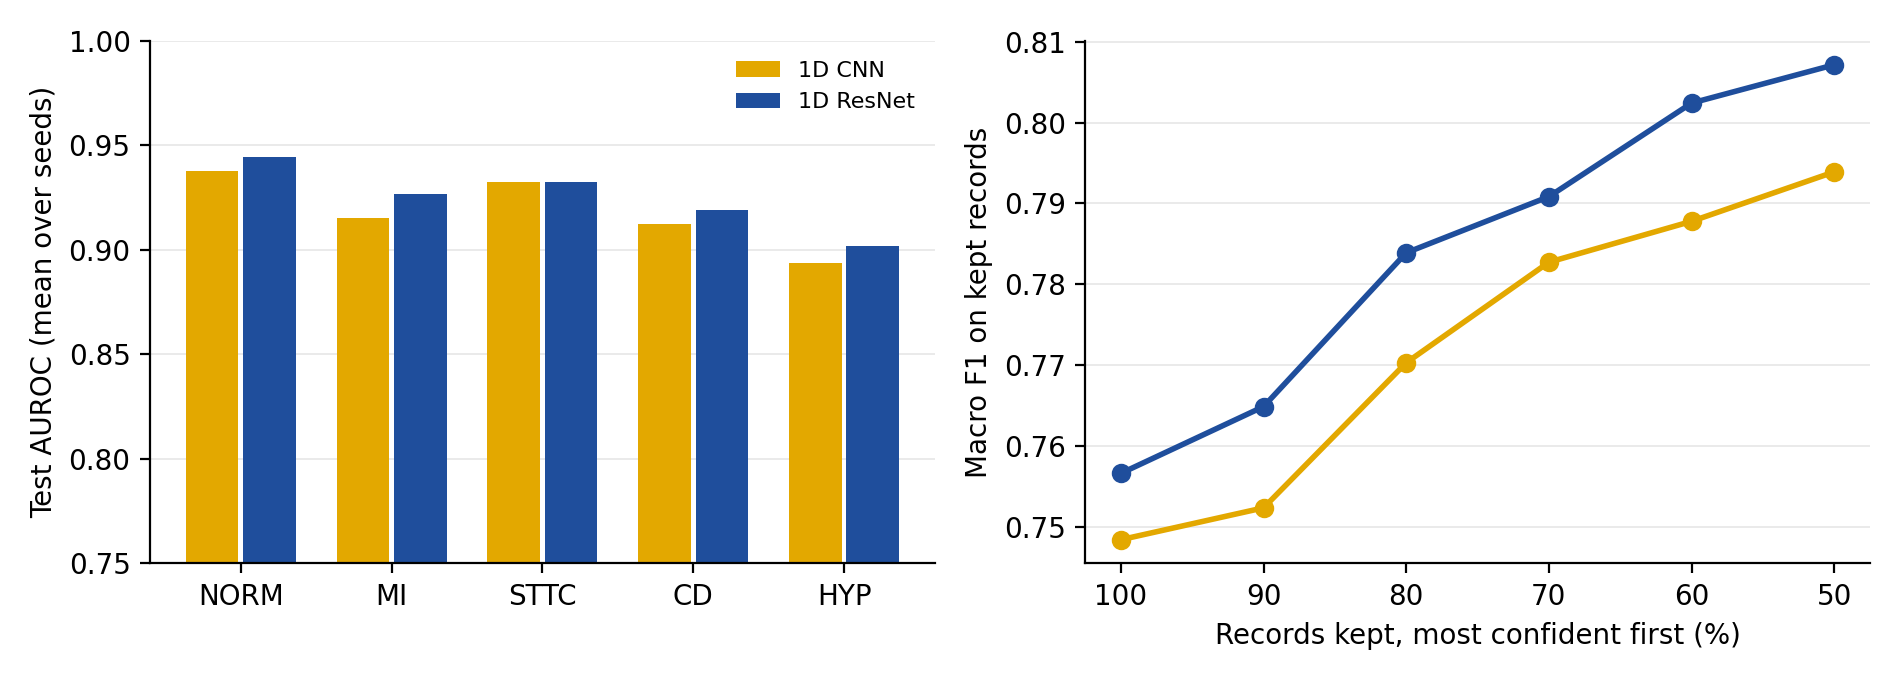

In [5]:
from cardionet.analysis import analyse
from IPython.display import Image, Markdown, display
analyse("checkpoints", "/kaggle/working/reports", "data/processed")
display(Markdown(open("/kaggle/working/reports/analysis.md").read()))
display(Image("/kaggle/working/reports/fig_auroc_selective.png"))

In [6]:
import shutil
for f in glob.glob("checkpoints/*_metrics.json") + glob.glob("checkpoints/*_predictions.npz") + glob.glob("checkpoints/*_best.pt") + ["data/processed/dataset_metadata.json"]:
    shutil.copy(f, "/kaggle/working/reports/")
shutil.rmtree("data/processed", ignore_errors=True)
shutil.rmtree("/kaggle/working/ptbxl", ignore_errors=True)
print(sorted(os.listdir("/kaggle/working/reports")))

['analysis.json', 'analysis.md', 'cnn_s17_best.pt', 'cnn_s17_metrics.json', 'cnn_s17_predictions.npz', 'cnn_s23_best.pt', 'cnn_s23_metrics.json', 'cnn_s23_predictions.npz', 'cnn_s31_best.pt', 'cnn_s31_metrics.json', 'cnn_s31_predictions.npz', 'cnn_s47_best.pt', 'cnn_s47_metrics.json', 'cnn_s47_predictions.npz', 'cnn_s59_best.pt', 'cnn_s59_metrics.json', 'cnn_s59_predictions.npz', 'dataset_metadata.json', 'fig_auroc_selective.pdf', 'fig_auroc_selective.png', 'resnet_s17_best.pt', 'resnet_s17_metrics.json', 'resnet_s17_predictions.npz', 'resnet_s23_best.pt', 'resnet_s23_metrics.json', 'resnet_s23_predictions.npz', 'resnet_s31_best.pt', 'resnet_s31_metrics.json', 'resnet_s31_predictions.npz', 'resnet_s47_best.pt', 'resnet_s47_metrics.json', 'resnet_s47_predictions.npz', 'resnet_s59_best.pt', 'resnet_s59_metrics.json', 'resnet_s59_predictions.npz']
